<a href="https://colab.research.google.com/github/adonaytetemke-wq/aspirin-structure-/blob/main/aspirin_structure.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aspirin: Visualizing a Remedy's Internal Structure
Aspirin (acetylsalicylic acid) is a simple, well-known remedy. In this notebook we draw its 2D structure, calculate its properties, find its functional groups, and view it as a rotatable 3D model.

## 1. Install tools

In [7]:
!pip install rdkit py3Dmol -q

## 2. Define aspirin from its SMILES
SMILES is a text code for a molecule's structure.

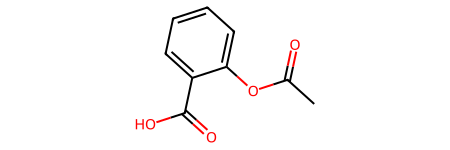

In [8]:
from rdkit import Chem
from rdkit.Chem import AllChem, Draw, Descriptors
import py3Dmol

smiles = "CC(=O)Oc1ccccc1C(=O)O"  # aspirin
mol = Chem.MolFromSmiles(smiles)
mol

## 3. 2D structure

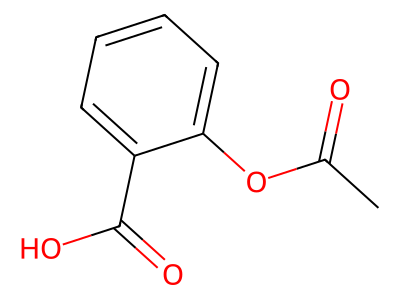

In [9]:
Draw.MolToImage(mol, size=(400, 300))

## 4. Key properties

In [10]:
print("Formula:", Chem.rdMolDescriptors.CalcMolFormula(mol))
print("Molecular weight:", round(Descriptors.MolWt(mol), 2), "g/mol")
print("H-bond donors:", Descriptors.NumHDonors(mol))
print("H-bond acceptors:", Descriptors.NumHAcceptors(mol))
print("LogP (fat vs water affinity):", round(Descriptors.MolLogP(mol), 2))

Formula: C9H8O4
Molecular weight: 180.16 g/mol
H-bond donors: 1
H-bond acceptors: 3
LogP (fat vs water affinity): 1.31


## 5. Functional groups
These parts of the molecule drive how aspirin behaves.

In [11]:
groups = {
    "Carboxylic acid (-COOH)": "C(=O)[OH]",
    "Ester (-COO-)": "[#6]C(=O)O[#6]",
    "Benzene ring": "c1ccccc1",
}
for name, smarts in groups.items():
    hits = mol.GetSubstructMatches(Chem.MolFromSmarts(smarts))
    print(f"{name}: {len(hits)} found")

Carboxylic acid (-COOH): 1 found
Ester (-COO-): 1 found
Benzene ring: 1 found


- **Benzene ring**: flat, rigid backbone.
- **Carboxylic acid**: makes aspirin acidic and helps it dissolve and bind.
- **Ester (acetyl group)**: the part that transfers to the COX enzyme, which blocks pain and inflammation signals.

## 6. Interactive 3D model
Drag to rotate, scroll to zoom.

In [12]:
mh = Chem.AddHs(mol)
AllChem.EmbedMolecule(mh, randomSeed=42)
AllChem.MMFFOptimizeMolecule(mh)

view = py3Dmol.view(width=450, height=400)
view.addModel(Chem.MolToMolBlock(mh), "mol")
view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
view.zoomTo()
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## Next
Protein folding: visualizing a well-known protein structure.

# New Section